# Khám phá dữ liệu ký hiệu Việt Nam — VieSign-10K

Notebook đọc **dữ liệu thực tế trên máy**, đối chiếu các manifest và cho phép xem video,
chuỗi khung hình, phân bố nhãn, người thực hiện và cách chia train/val/test.
Không thay đổi dữ liệu gốc, không huấn luyện và không thay dữ liệu của ứng dụng.

**Chạy:** mở bằng VS Code/Jupyter, chọn Python của `.venv`, rồi **Run All**.
Nếu thiếu thư viện: từ gốc dự án chạy `.\.venv\Scripts\python.exe -m pip install -r notebooks/requirements.txt`.
Các biểu đồ và báo cáo nhỏ được xuất vào `notebooks/artifacts/viesign/`.

**Cách đọc:** 10K là corpus; 1.182 lớp và 447 lớp là các bộ con, không cộng số video với nhau.
Video đơn lẻ dùng cho nhận diện ký hiệu cô lập, không tự chứng minh khả năng dịch câu liên tục.

In [1]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import json
import math
import mimetypes
import unicodedata
import html
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Video, Markdown, clear_output

SEED = 42
FULL_VIDEO_SCAN = False  # True: đọc metadata và thử giải mã mọi video; có thể mất nhiều phút.
PROBE_SAMPLE_SIZE = 64
DATA_ROOT_OVERRIDE = None  # Có thể đặt Path(r"D:\CLB_AI\Duan\data_v2\VieSign10K\VieSign10K")

def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'data_v2').is_dir() and (candidate / 'app').is_dir():
            return candidate
    raise FileNotFoundError('Hãy chạy notebook bên trong thư mục dự án Duan.')

PROJECT_ROOT = find_project_root()
if DATA_ROOT_OVERRIDE is None:
    candidates = sorted((PROJECT_ROOT / 'data_v2').rglob('ISLR_447_all_rows.csv'))
    if len(candidates) != 1:
        raise RuntimeError(f'Tìm thấy {len(candidates)} manifest. Hãy đặt DATA_ROOT_OVERRIDE.')
    DATA_ROOT = candidates[0].parent
else:
    DATA_ROOT = Path(DATA_ROOT_OVERRIDE)
VIDEO_ROOT = DATA_ROOT / 'video_raw'
ARTIFACTS = PROJECT_ROOT / 'notebooks' / 'artifacts' / 'viesign'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.family': 'DejaVu Sans'})
SPLITS = ['train', 'val', 'test']
COLORS = {'train': '#247BA0', 'val': '#F0A202', 'test': '#8B5FBF'}

def save_figure(name):
    plt.savefig(ARTIFACTS / name, dpi=150, bbox_inches='tight')

print('Dữ liệu:', DATA_ROOT)
print('OpenCV:', cv2.__version__)

Dữ liệu: D:\CLB_AI\Duan\data_v2\VieSign10K\VieSign10K
OpenCV: 4.13.0


## 1. Cấu trúc và ý nghĩa các bảng

- `video_raw/`: video `.mp4` và `.webm`, tên file nối với `ID_video`.
- `ISLR_447_all_rows.csv`: manifest nguồn 7.664 video; `split` là cách chia cũ,
  `split_signer_independent` là cách chia mới, có cả trạng thái `excluded`.
- `ISLR_447classes_4252videos.csv`: bộ con 447 lớp. **Bản tải này chỉ có cột `split`,
  nhưng giá trị đã là cách chia mới**; notebook đối chiếu theo ID để xác nhận.
- `signer_assignment.csv`: phân vùng và số video của người thực hiện.
- `class_split_audit.csv`, `validation_checks.csv`, `split_summary.json`: tài liệu đối chiếu.

Nhãn `Meaning` được giữ nguyên, kể cả dấu gạch dưới và mã chưa rõ nghĩa.
Không suy luận nhãn/vùng miền từ tên file, trang phục hay phông nền.

In [2]:
def read_manifest(name):
    return pd.read_csv(DATA_ROOT / name, dtype=str, encoding='utf-8-sig', keep_default_na=False)

source = read_manifest('ISLR_447_all_rows.csv')
filtered = read_manifest('ISLR_447classes_4252videos.csv')
signer_assignment = read_manifest('signer_assignment.csv')
class_audit = read_manifest('class_split_audit.csv')
supplied_checks = read_manifest('validation_checks.csv')
summary = json.loads((DATA_ROOT / 'split_summary.json').read_text(encoding='utf-8'))
for frame in (source, filtered):
    frame['duration_s'] = pd.to_numeric(frame['Duration (s)'], errors='coerce')
    frame['label_display'] = frame['Meaning'].str.replace('_', ' ', regex=False)

structure = pd.DataFrame([
    {'file': p.name, 'kind': 'directory' if p.is_dir() else 'file',
     'size_KB': round(p.stat().st_size / 1024, 1) if p.is_file() else np.nan}
    for p in sorted(DATA_ROOT.iterdir())
])
display(structure)
display(pd.DataFrame([
    {'manifest': 'source', 'rows': len(source), 'classes': source.Meaning.nunique(),
     'signers': source.Signer.nunique(), 'columns': ', '.join(source.columns)},
    {'manifest': 'filtered', 'rows': len(filtered), 'classes': filtered.Meaning.nunique(),
     'signers': filtered.Signer.nunique(), 'columns': ', '.join(filtered.columns)}
]))
display(source.head(10))

,file,kind,size_KB
0,class_split_audit.csv,file,47.6
1,ISLR_447_all_rows.csv,file,306.1
2,ISLR_447classes_4252videos.csv,file,139.7
3,README_447.md,file,8.7
4,signer_assignment.csv,file,0.9
5,split_summary.json,file,1.2
6,validation_checks.csv,file,0.2
7,video_raw,directory,NaN


,manifest,rows,classes,signers,columns
0,source,7664,1182,57,"ID_video, Meaning, Duration (s), split, Signer, split_signer_independent, duration_s, ..."
1,filtered,4252,447,50,"ID_video, Meaning, Duration (s), split, Signer, duration_s, label_display"


,ID_video,Meaning,Duration (s),split,Signer,split_signer_independent,duration_s,label_display
0,A0000,sợ_hãi,2.2022,train,1,excluded,2.202200,sợ hãi
1,A0001,tự_tin,2.969633333,train,1,train,2.969633,tự tin
2,A0002,tự_tin,2.869533333,train,1,train,2.869533,tự tin
3,A0003,tự_tin,2.435766667,test,1,train,2.435767,tự tin
4,A0004,lễ_phép,2.3023,train,2,train,2.302300,lễ phép
5,A0005,vâng_lời,3.036366667,valid,2,excluded,3.036367,vâng lời
6,A0006,vâng_lời,2.4024,valid,2,excluded,2.402400,vâng lời
7,A0007,vâng_lời,2.535866667,train,2,excluded,2.535867,vâng lời
8,A0008,độc_ác,1.568233333,train,3,train,1.568233,độc ác
9,A0009,độc_ác,3.236566667,train,3,train,3.236567,độc ác


## 2. Kiểm kê video và độ bao phủ nhãn

Phân biệt số file đang có trên ổ đĩa với số video đã có nhãn trong các CSV.
Những file ngoài manifest **chưa có nhãn trong gói hiện tại**, không được tự gán nghĩa
hay tự đưa vào tập huấn luyện. So sánh với 10.515 video được README mô tả chỉ là kiểm kê;
không tự kết luận file dư là trùng lặp hoặc bị hỏng.

In [3]:
video_paths = sorted(p for p in VIDEO_ROOT.rglob('*')
                     if p.is_file() and p.suffix.lower() in {'.mp4', '.webm'})
files = pd.DataFrame([
    {'ID_video': p.stem, 'path': str(p), 'relative_path': p.relative_to(DATA_ROOT).as_posix(),
     'extension': p.suffix.lower(), 'size_bytes': p.stat().st_size}
    for p in video_paths
])
assert len(files), 'Không tìm thấy video trong video_raw.'
duplicate_ids = files[files.ID_video.duplicated(keep=False)].sort_values('ID_video')
source_ids = set(source.ID_video)
benchmark_ids = set(filtered.ID_video)
disk_ids = set(files.ID_video)
unlisted = files[~files.ID_video.isin(source_ids)].copy()
missing_source = source[~source.ID_video.isin(disk_ids)]
missing_benchmark = filtered[~filtered.ID_video.isin(disk_ids)]

overview = pd.DataFrame([
    ['Video theo mô tả README', 10515],
    ['File video thực có', len(files)],
    ['ID video duy nhất trên ổ đĩa', files.ID_video.nunique()],
    ['ID có nhãn trong manifest nguồn', source.ID_video.nunique()],
    ['ID thuộc benchmark 447 lớp', filtered.ID_video.nunique()],
    ['File ngoài manifest nguồn', len(unlisted)],
    ['Video nguồn thiếu file', len(missing_source)],
    ['Video benchmark thiếu file', len(missing_benchmark)],
    ['Dung lượng video (GB thập phân)', round(files.size_bytes.sum() / 1e9, 3)]
], columns=['Chỉ số', 'Giá trị'])
display(overview)
display(files.groupby('extension').agg(files=('ID_video', 'size'),
                                       total_GB=('size_bytes', lambda x: x.sum()/1e9)))
print('Các ID trùng tên:', len(duplicate_ids))
if len(duplicate_ids):
    display(duplicate_ids.head(20))
    raise ValueError('Có nhiều file cùng ID; cần giải quyết trước khi nối manifest.')

source = source.merge(files, on='ID_video', how='left', validate='one_to_one')
filtered = filtered.merge(files, on='ID_video', how='left', validate='one_to_one')
display(unlisted[['ID_video', 'extension']].head(12))

,Chỉ số,Giá trị
0,Video theo mô tả README,10515.000
1,File video thực có,10553.000
2,ID video duy nhất trên ổ đĩa,10553.000
3,ID có nhãn trong manifest nguồn,7664.000
4,ID thuộc benchmark 447 lớp,4252.000
5,File ngoài manifest nguồn,2889.000
6,Video nguồn thiếu file,0.000
7,Video benchmark thiếu file,0.000
8,Dung lượng video (GB thập phân),6.251


,files,total_GB
extension,,
.mp4,6344,2.798358
.webm,4209,3.452350


Các ID trùng tên: 0


,ID_video,extension
10,A0010,.mp4
121,A0147,.mp4
532,A0570,.mp4
1062,B0186,.mp4
1225,B0363,.mp4
1226,B0364,.mp4
1741,B1010,.mp4
1808,D0002,.webm
1809,D0003,.webm
1810,D0004,.webm


## 3. Đối chiếu cách chia tập — tránh lẫn hai giao thức

Dùng `source.split_signer_independent` làm cột chuẩn `benchmark_split`.
Chỉ coi file filtered tương đương khi ID, nhãn, người thực hiện và split đều khớp.
Kiểm tra này quan trọng vì hướng dẫn README và cột thực có khác nhau.

In [4]:
benchmark = source[source.split_signer_independent.isin(SPLITS)].copy()
benchmark['benchmark_split'] = benchmark.split_signer_independent
filtered_split_col = ('split_signer_independent'
                      if 'split_signer_independent' in filtered.columns else 'split')
comparison = filtered[['ID_video', 'Meaning', 'Signer', filtered_split_col]].merge(
    benchmark[['ID_video', 'Meaning', 'Signer', 'benchmark_split']],
    on='ID_video', suffixes=('_filtered', '_source'), how='outer', indicator=True,
    validate='one_to_one')
same_metadata = (comparison.Meaning_filtered.eq(comparison.Meaning_source)
                 & comparison.Signer_filtered.eq(comparison.Signer_source)).all()
same_splits = comparison[filtered_split_col].eq(comparison.benchmark_split).all()
signer_sets = {s: set(benchmark.loc[benchmark.benchmark_split.eq(s), 'Signer']) for s in SPLITS}
class_sets = {s: set(benchmark.loc[benchmark.benchmark_split.eq(s), 'Meaning']) for s in SPLITS}
check_rows = [
    ('Manifest nguồn không trùng ID', not source.ID_video.duplicated().any()),
    ('Manifest filtered không trùng ID', not filtered.ID_video.duplicated().any()),
    ('Filtered và retained source có cùng ID', comparison['_merge'].eq('both').all()),
    ('Nhãn và signer khớp giữa hai manifest', same_metadata),
    ('Split filtered khớp cách chia mới', same_splits),
    ('Mọi video nguồn đều có file', len(missing_source) == 0),
    ('Thời lượng nguồn hợp lệ', source.duration_s.notna().all() and source.duration_s.gt(0).all()),
    ('Signer không rỗng', source.Signer.str.strip().ne('').all()),
    ('Số video khớp split_summary', len(benchmark) == summary['retained_videos']),
    ('Số lớp khớp split_summary', benchmark.Meaning.nunique() == summary['retained_classes'])
]
for a, b in combinations(SPLITS, 2):
    check_rows.append((f'Không giao signer {a}/{b}', signer_sets[a].isdisjoint(signer_sets[b])))
for s in SPLITS:
    check_rows.append((f'Đủ lớp trong {s}', class_sets[s] == set(benchmark.Meaning)))
    check_rows.append((f'Số video {s} khớp summary',
                       int(benchmark.benchmark_split.eq(s).sum()) == summary['splits'][s]['videos']))
checks = pd.DataFrame(check_rows, columns=['Kiểm tra', 'passed'])
display(checks)
if not checks.passed.all():
    raise ValueError('Đối chiếu chưa đạt. Đọc bảng trên trước khi tiếp tục.')

split_stats = benchmark.groupby('benchmark_split').agg(
    videos=('ID_video', 'size'), classes=('Meaning', 'nunique'), signers=('Signer', 'nunique')
).reindex(SPLITS)
split_stats['percent'] = (split_stats.videos / len(benchmark) * 100).round(2)
display(split_stats)
old_overlap = pd.DataFrame([
    {'pair': f'{a}/{b}', 'shared_signers': len(set(source.loc[source.split.eq(a), 'Signer'])
                                              & set(source.loc[source.split.eq(b), 'Signer']))}
    for a, b in combinations(sorted(source.split.unique()), 2)
])
display(old_overlap)
print('File filtered thực dùng cột:', filtered_split_col)
print('Đã xác nhận nhãn/người thực hiện/split theo ID, không dựa vào tên file.')

,Kiểm tra,passed
0,Manifest nguồn không trùng ID,True
1,Manifest filtered không trùng ID,True
2,Filtered và retained source có cùng ID,True
3,Nhãn và signer khớp giữa hai manifest,True
4,Split filtered khớp cách chia mới,True
5,Mọi video nguồn đều có file,True
6,Thời lượng nguồn hợp lệ,True
7,Signer không rỗng,True
8,Số video khớp split_summary,True
9,Số lớp khớp split_summary,True


,videos,classes,signers,percent
benchmark_split,,,,
train,2344,447,25,55.13
val,1021,447,13,24.01
test,887,447,12,20.86


,pair,shared_signers
0,test/train,52
1,test/valid,47
2,train/valid,48


File filtered thực dùng cột: split
Đã xác nhận nhãn/người thực hiện/split theo ID, không dựa vào tên file.


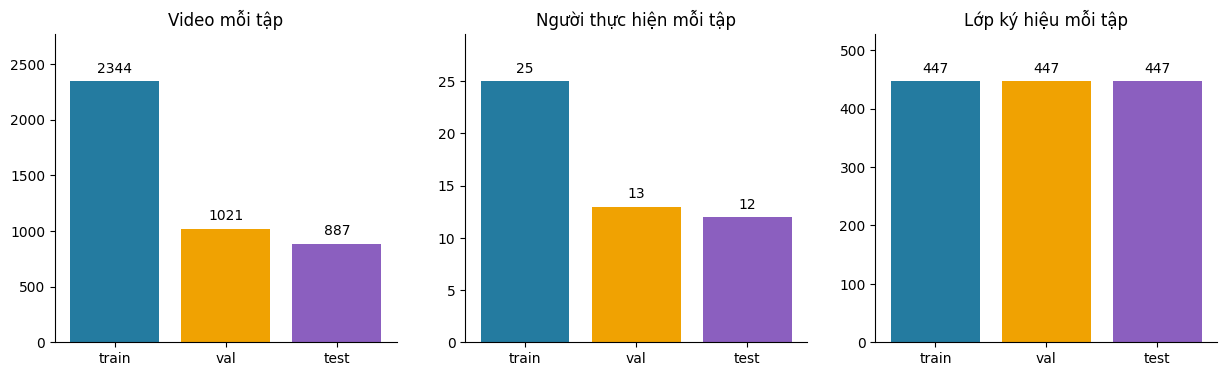

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ['videos', 'signers', 'classes'],
                           ['Video mỗi tập', 'Người thực hiện mỗi tập', 'Lớp ký hiệu mỗi tập']):
    bars = ax.bar(SPLITS, split_stats[metric], color=[COLORS[s] for s in SPLITS])
    ax.bar_label(bars, padding=4)
    ax.set_title(title)
    ax.set_ylim(0, split_stats[metric].max() * 1.18)
save_figure('01_split_overview.png')
plt.show()

## 4. Từ vựng và mất cân bằng dữ liệu

Biểu đồ bên dưới dùng benchmark 447 lớp. Nhóm head/medium/tail được xác định
**chỉ từ số video train**: head ≥ 6; medium 3–5; tail 1–2.
Số lượng video cao không đồng nghĩa động tác hoặc nhãn đã được kiểm duyệt.

benchmark_split,train,val,test,total,train_group
Meaning,,,,,
tình_cảm,22,1,8,31,head
giúp_đỡ,14,8,4,26,head
đầu_đĩa,19,3,3,25,head
thật_thà,14,8,3,25,head
quần_bò,15,5,4,24,head
xe_máy,19,3,2,24,head
xe_buýt,15,7,2,24,head
điều_hòa,12,7,4,23,head
tự_lập,14,2,6,22,head


,classes,train_videos,test_videos
train_group,,,
head,182,1632,426
medium,135,532,268
tail,130,180,193


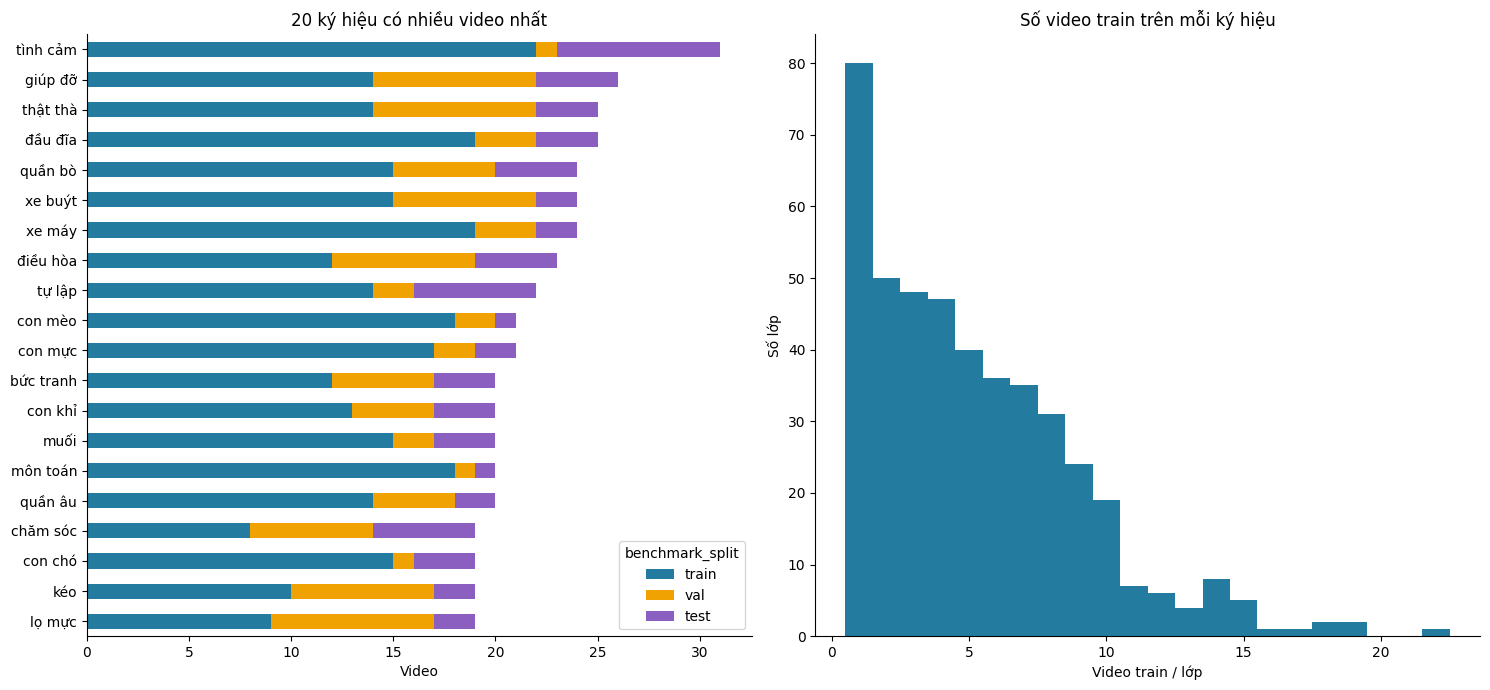

130/447 lớp chỉ có 1–2 video train.


benchmark_split,train,val,test,total,train_group
Meaning,,,,,
buông_màn,1,1,1,3,tail
bìa_vở,1,1,1,3,tail
bực_mình,1,1,1,3,tail
c,1,1,1,3,tail
chiếc_gối,1,1,1,3,tail
cháu_ngoại,1,1,1,3,tail
cháu_nội,1,1,1,3,tail
châm_cứu,1,1,1,3,tail
chùa,1,1,1,3,tail


In [6]:
class_counts = pd.crosstab(benchmark.Meaning, benchmark.benchmark_split).reindex(columns=SPLITS, fill_value=0)
class_counts['total'] = class_counts[SPLITS].sum(axis=1)
class_counts['train_group'] = np.select(
    [class_counts.train.ge(6), class_counts.train.ge(3)], ['head', 'medium'], default='tail')
display(class_counts.sort_values('total', ascending=False).head(20))
display(class_counts.groupby('train_group').agg(classes=('total', 'size'),
                                               train_videos=('train', 'sum'), test_videos=('test', 'sum')))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
top = class_counts.nlargest(20, 'total')[SPLITS].iloc[::-1]
top.index = top.index.str.replace('_', ' ', regex=False)
top.plot.barh(stacked=True, ax=axes[0], color=[COLORS[s] for s in SPLITS])
axes[0].set_title('20 ký hiệu có nhiều video nhất'); axes[0].set_xlabel('Video')
axes[0].set_ylabel('')
axes[1].hist(class_counts.train, bins=np.arange(0.5, class_counts.train.max()+1.5), color=COLORS['train'])
axes[1].set_title('Số video train trên mỗi ký hiệu')
axes[1].set_xlabel('Video train / lớp'); axes[1].set_ylabel('Số lớp')
fig.tight_layout(); save_figure('02_class_distribution.png'); plt.show()

rare = class_counts[class_counts.train.le(2)].sort_values(['train', 'total'])
print(f'{len(rare)}/{len(class_counts)} lớp chỉ có 1–2 video train.')
display(rare.head(12))

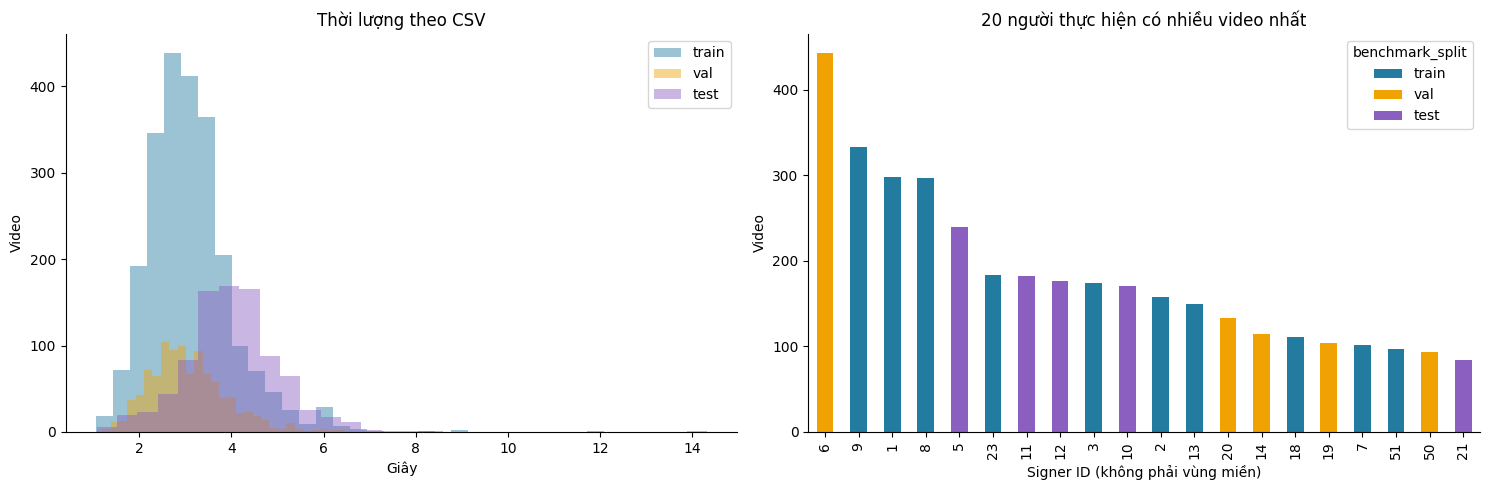

,count,mean,std,min,25%,50%,75%,max
benchmark_split,,,,,,,,
test,887.0,4.041,1.067,1.080,3.44,3.962,4.600,14.32
train,2344.0,3.101,0.920,1.067,2.48,2.970,3.520,12.08
val,1021.0,3.069,0.853,1.200,2.48,2.960,3.537,6.64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for split in SPLITS:
    values = benchmark.loc[benchmark.benchmark_split.eq(split), 'duration_s']
    axes[0].hist(values, bins=30, alpha=0.45, label=split, color=COLORS[split])
axes[0].legend(); axes[0].set_title('Thời lượng theo CSV')
axes[0].set_xlabel('Giây'); axes[0].set_ylabel('Video')
signer_counts = pd.crosstab(benchmark.Signer, benchmark.benchmark_split).reindex(columns=SPLITS, fill_value=0)
signer_counts = signer_counts.loc[signer_counts.sum(axis=1).sort_values(ascending=False).index]
signer_counts.head(20).plot.bar(stacked=True, ax=axes[1], color=[COLORS[s] for s in SPLITS])
axes[1].set_title('20 người thực hiện có nhiều video nhất')
axes[1].set_xlabel('Signer ID (không phải vùng miền)'); axes[1].set_ylabel('Video')
fig.tight_layout(); save_figure('03_duration_signers.png'); plt.show()
display(benchmark.groupby('benchmark_split').duration_s.describe().round(3))

## 5. Đọc thử video: codec, FPS, độ phân giải và thời lượng

Mặc định lấy mẫu có seed cố định từ **toàn bộ file trên ổ đĩa**, phân tầng theo đuôi file.
Đọc metadata bằng OpenCV và thử giải mã frame đầu + frame giữa; đây **không phải kiểm tra
toàn bộ frame** và chưa phát hiện trùng nội dung/nhãn sai.
Đặt `FULL_VIDEO_SCAN=True` để kiểm tra metadata/khả năng đọc mẫu frame của mọi file.
Thời lượng tính từ frame count/FPS có thể chỉ gần đúng với video tốc độ khung hình biến đổi.

Đã kiểm tra 64/10553 video; đọc được hai frame mẫu: 64.


,ID_video,extension,opened,fps,frame_count,width,height,duration_decoded_s,first_frame_ok,middle_frame_ok,duration_s,duration_delta_s,sample_decode_ok
0,A0086,.mp4,True,29.97003,83,562,476,2.769433,True,True,2.769433,3.333334e-10,True
1,A0245,.mp4,True,29.97003,103,524,474,3.436767,True,True,3.436767,-3.333334e-10,True
2,A0495,.mp4,True,29.97003,78,574,476,2.602600,True,True,2.602600,4.440892e-16,True
3,A0807,.mp4,True,29.97003,106,544,478,3.536867,True,True,3.536867,-3.333334e-10,True
4,A0827,.mp4,True,29.97003,59,456,480,1.968633,True,True,1.968633,3.333334e-10,True
5,B0319,.mp4,True,29.97003,90,596,462,3.003000,True,True,3.003000,0.000000e+00,True
6,B0563,.mp4,True,25.00000,85,596,458,3.400000,True,True,3.400000,0.000000e+00,True
7,B0671,.mp4,True,25.00000,59,616,464,2.360000,True,True,2.360000,0.000000e+00,True
8,B0673,.mp4,True,25.00000,48,616,464,1.920000,True,True,1.920000,0.000000e+00,True
9,B0707,.mp4,True,29.97003,60,936,706,2.002000,True,True,2.002000,4.440892e-16,True


sample_videos
extension width height               
.mp4      308   342                 1
          402   476                 1
          410   478                 1
          432   464                 1
          440   466                 1
          448   462                 1
          456   480                 1
          474   472                 1
          498   472                 1
          502   458                 1
          504   478                 1
          514   472                 1
          524   474                 1
          526   450                 1
          530   448                 1
          532   440                 1
          534   442                 1
          540   460                 1
          542   450                 1
          544   478                 1
          556   478                 1
          562   442                 1
                476                 1
          574   438                 1
                476                 1
          596   458                 1
                462                 1
          616   464                 2
          632   464                 1
          936   706                 1
          976   720                 1
.webm     1280  720                32

,duration_s,duration_decoded_s,duration_delta_s
count,47.000,47.000,47.0
mean,3.412,3.412,0.0
std,0.948,0.948,0.0
min,1.920,1.920,-0.0
25%,2.785,2.785,0.0
50%,3.320,3.320,0.0
75%,3.737,3.737,0.0
max,5.800,5.800,0.0


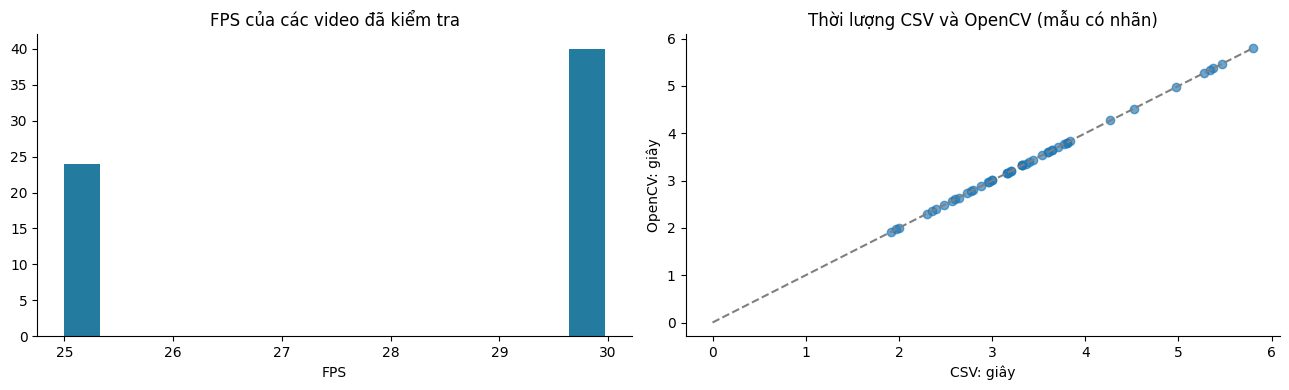

In [8]:
if FULL_VIDEO_SCAN:
    probe_files = files.copy()
else:
    sampled = []
    per_ext = max(1, math.ceil(PROBE_SAMPLE_SIZE / files.extension.nunique()))
    for _, group in files.groupby('extension'):
        sampled.append(group.sample(min(per_ext, len(group)), random_state=SEED))
    probe_files = pd.concat(sampled).sort_values('ID_video')

def probe_video(row):
    cap = cv2.VideoCapture(row.path)
    result = {'ID_video': row.ID_video, 'extension': row.extension, 'opened': cap.isOpened(),
              'fps': np.nan, 'frame_count': np.nan, 'width': np.nan, 'height': np.nan,
              'duration_decoded_s': np.nan}
    try:
        if not cap.isOpened():
            return {**result, 'first_frame_ok': False, 'middle_frame_ok': False}
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        first_ok, _ = cap.read()
        cap.set(cv2.CAP_PROP_POS_FRAMES, max(count // 2, 0))
        middle_ok, _ = cap.read()
        return {**result, 'fps': fps, 'frame_count': count, 'width': width, 'height': height,
                'duration_decoded_s': count/fps if fps > 0 else np.nan,
                'first_frame_ok': first_ok, 'middle_frame_ok': middle_ok}
    except Exception as error:
        return {**result, 'first_frame_ok': False, 'middle_frame_ok': False, 'error': str(error)}
    finally:
        cap.release()

records = []
for i, row in enumerate(probe_files.itertuples(index=False), 1):
    records.append(probe_video(row))
    if FULL_VIDEO_SCAN and i % 500 == 0:
        print(f'Đã đọc {i}/{len(probe_files)} video')
probe = pd.DataFrame(records).merge(source[['ID_video', 'duration_s']], on='ID_video', how='left', validate='one_to_one')
probe['duration_delta_s'] = probe.duration_decoded_s - probe.duration_s
probe['sample_decode_ok'] = probe.opened & probe.first_frame_ok & probe.middle_frame_ok
print(f'Đã kiểm tra {len(probe)}/{len(files)} video; đọc được hai frame mẫu: {probe.sample_decode_ok.sum()}.')
display(probe.head(12))
display(probe.groupby(['extension', 'width', 'height']).size().rename('sample_videos').to_frame())
probe_failures = probe[~probe.sample_decode_ok]
if len(probe_failures):
    display(probe_failures)
known_durations = probe.dropna(subset=['duration_delta_s'])
if len(known_durations):
    display(known_durations[['duration_s', 'duration_decoded_s', 'duration_delta_s']].describe().round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(probe.fps.dropna(), bins=15, color='#247BA0')
axes[0].set_title('FPS của các video đã kiểm tra'); axes[0].set_xlabel('FPS')
axes[1].scatter(known_durations.duration_s, known_durations.duration_decoded_s, alpha=0.65)
if len(known_durations):
    limit = max(known_durations.duration_s.max(), known_durations.duration_decoded_s.max())
    axes[1].plot([0, limit], [0, limit], '--', color='gray')
axes[1].set_title('Thời lượng CSV và OpenCV (mẫu có nhãn)')
axes[1].set_xlabel('CSV: giây'); axes[1].set_ylabel('OpenCV: giây')
fig.tight_layout(); save_figure('04_video_probe.png'); plt.show()

## 6. Xem động tác qua chuỗi khung hình

Chọn một nhãn để so sánh nhiều video/người thực hiện. Mỗi hàng là một video,
các cột đi từ đầu tới cuối clip. Đây là mẫu quan sát, không phải xác nhận nhãn đúng.
Các thời điểm lấy mẫu dựa trên frame index, không phải mốc bắt đầu/kết thúc động tác đã gán nhãn.

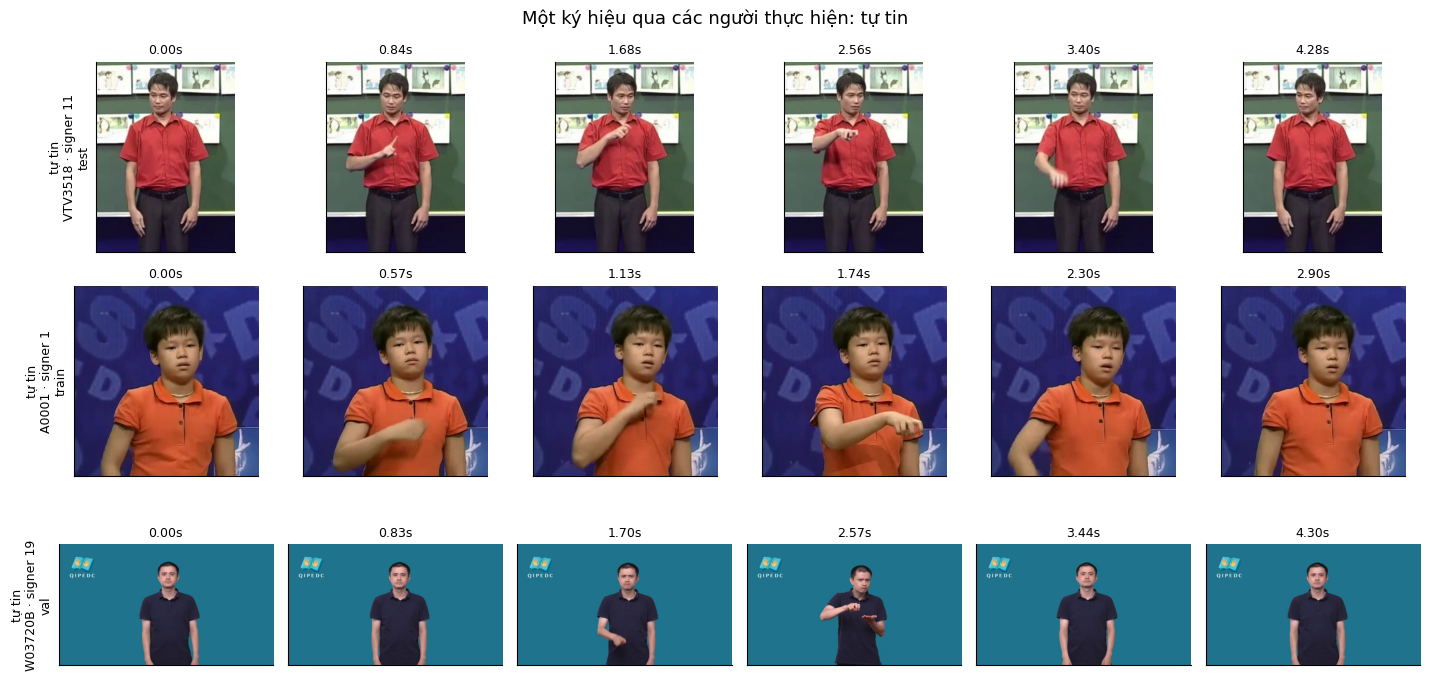

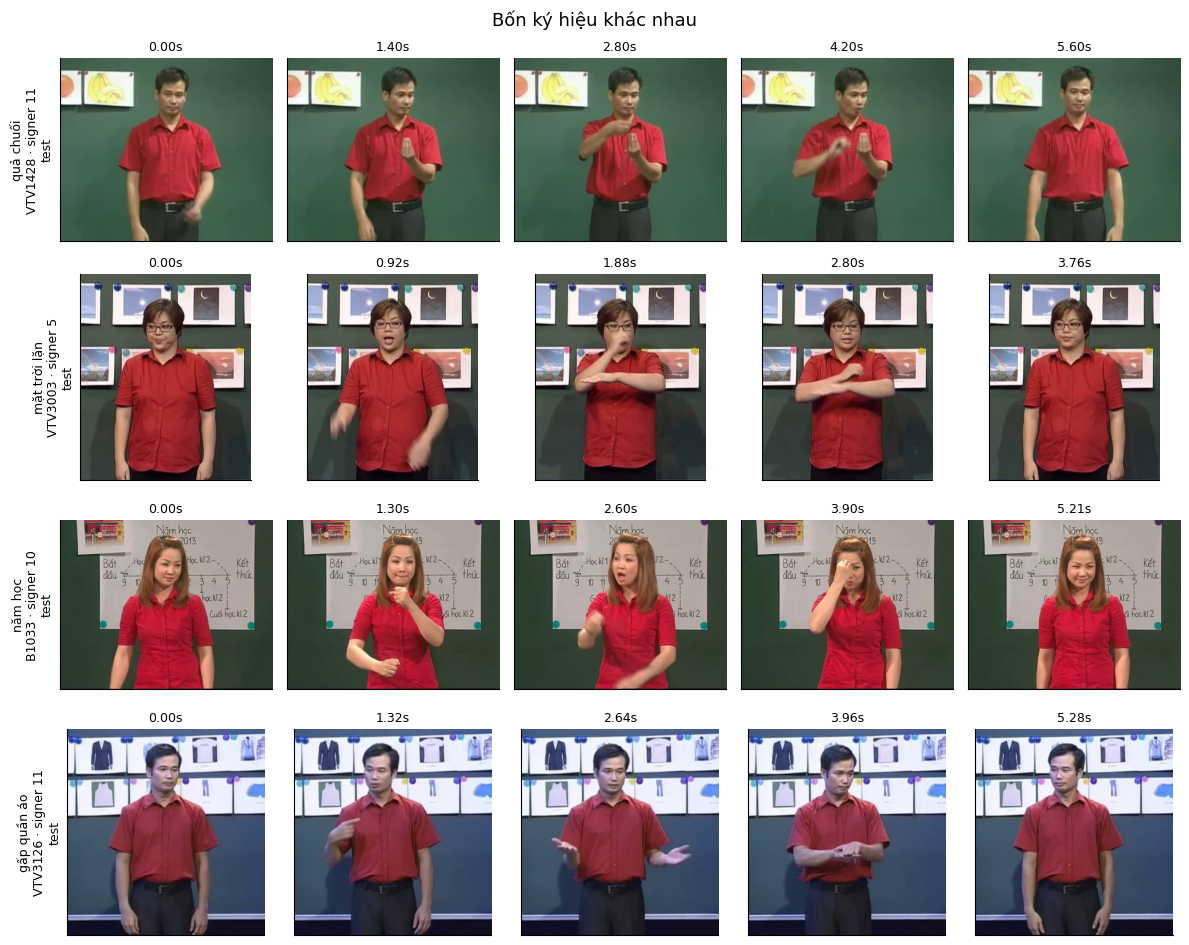

In [9]:
def contact_sheet(rows, frame_samples=6, title='', output_name=None):
    rows = rows.reset_index(drop=True)
    if rows.empty:
        print('Không có video phù hợp.'); return
    fig, axes = plt.subplots(len(rows), frame_samples, figsize=(frame_samples*2.4, len(rows)*2.4), squeeze=False)
    for r, row in rows.iterrows():
        cap = cv2.VideoCapture(row.path)
        try:
            count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = cap.get(cv2.CAP_PROP_FPS)
            indices = np.linspace(0, max(count-2, 0), frame_samples).astype(int)
            for c, index in enumerate(indices):
                ax = axes[r, c]
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(index)); ok, frame = cap.read()
                if ok:
                    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
                else:
                    ax.text(.5, .5, 'Không đọc được frame', ha='center', transform=ax.transAxes)
                ax.set_xticks([]); ax.set_yticks([])
                ax.set_title(f'{index/fps:.2f}s' if fps > 0 else f'frame {index}', fontsize=9)
                if c == 0:
                    ax.set_ylabel(f'{row.label_display}\n{row.ID_video} · signer {row.Signer}\n{row.benchmark_split}', fontsize=9)
        finally:
            cap.release()
    fig.suptitle(title, fontsize=13); fig.tight_layout()
    if output_name: save_figure(output_name)
    plt.show()

# Ưu tiên nhãn phổ biến và nhiều người, lấy một ví dụ mỗi split để so sánh.
EXAMPLE_LABEL = 'tự_tin' if 'tự_tin' in set(benchmark.Meaning) else class_counts.total.idxmax()
examples = benchmark[benchmark.Meaning.eq(EXAMPLE_LABEL)].sort_values(['benchmark_split', 'Signer', 'ID_video'])
examples = examples.groupby('benchmark_split', sort=False).head(1)
contact_sheet(examples, title=f'Một ký hiệu qua các người thực hiện: {EXAMPLE_LABEL.replace("_", " ")}',
              output_name='05_same_sign_across_signers.png')

diverse = benchmark.sort_values('ID_video').drop_duplicates('Meaning').sample(4, random_state=SEED)
contact_sheet(diverse, frame_samples=5, title='Bốn ký hiệu khác nhau', output_name='06_diverse_signs.png')

## 7. Phát video trực tiếp và trình duyệt tương tác

Hai video mẫu bên dưới được nhúng để bản notebook đã chạy có thể xem lại.
Điều khiển tương tác cần kernel đang chạy và `ipywidgets`; chọn nhãn, split, signer rồi bấm xem.
Trình duyệt phải hỗ trợ codec của video gốc; nếu OpenCV đọc được mà trình duyệt không phát,
hãy mở đường dẫn video bằng trình phát trên máy. Không tự chuyển mã hay ghi đè video gốc.

In [10]:
def show_video(row, max_mb=12):
    display(Markdown(f'**{row.label_display}** · `{row.ID_video}` · signer `{row.Signer}` · `{row.benchmark_split}`'))
    print('File:', row.path)
    if Path(row.path).stat().st_size > max_mb * 1024**2:
        print(f'Video lớn hơn {max_mb} MB; mở file trực tiếp để tránh làm notebook quá nặng.')
        return
    mime = 'video/webm' if Path(row.path).suffix.lower() == '.webm' else 'video/mp4'
    display(Video(filename=row.path, embed=True, mimetype=mime, width=560))

preview_rows = benchmark.sort_values('ID_video').drop_duplicates('extension').head(2)
for _, row in preview_rows.iterrows():
    show_video(row)

**tự tin** · `A0001` · signer `1` · `train`

File: D:\CLB_AI\Duan\data_v2\VieSign10K\VieSign10K\video_raw\A0001.mp4


**bực mình** · `D0036` · signer `19` · `val`

File: D:\CLB_AI\Duan\data_v2\VieSign10K\VieSign10K\video_raw\D0036.webm


In [11]:
try:
    import ipywidgets as widgets
except ImportError:
    print('Cài ipywidgets để dùng bộ chọn. Các video mẫu phía trên vẫn xem được.')
else:
    def search_key(value):
        value = unicodedata.normalize('NFD', str(value).casefold().replace('_', ' ')).replace('đ', 'd')
        return ''.join(c for c in value if not unicodedata.combining(c))

    search = widgets.Text(description='Tìm nhãn:', placeholder='Có thể gõ không dấu')
    label = widgets.Dropdown(description='Ký hiệu:', layout=widgets.Layout(width='550px'))
    split = widgets.Dropdown(description='Tập:', options=[('Tất cả', 'all')] + [(s, s) for s in SPLITS])
    signer = widgets.Dropdown(description='Signer:', options=[('Tất cả', 'all')])
    video = widgets.Dropdown(description='Video:', layout=widgets.Layout(width='550px'))
    play = widgets.Button(description='Xem video + khung hình', button_style='info', layout=widgets.Layout(width='230px'))
    viewer = widgets.Output()

    def update_videos(*_):
        part = benchmark[benchmark.Meaning.eq(label.value)]
        if split.value != 'all': part = part[part.benchmark_split.eq(split.value)]
        if signer.value != 'all': part = part[part.Signer.eq(signer.value)]
        previous_video = video.value
        video.options = [(f'{r.ID_video} | signer {r.Signer} | {r.benchmark_split}', r.ID_video)
                         for r in part.sort_values('ID_video').itertuples()]
        valid_ids = [value for _, value in video.options]
        video.value = previous_video if previous_video in valid_ids else (valid_ids[0] if valid_ids else None)
        play.disabled = part.empty

    def update_signers(*_):
        part = benchmark[benchmark.Meaning.eq(label.value)]
        if split.value != 'all': part = part[part.benchmark_split.eq(split.value)]
        previous_signer = signer.value
        signer.options = [('Tất cả', 'all')] + [(s, s) for s in sorted(part.Signer.unique(), key=int)]
        signer.value = previous_signer if previous_signer in [value for _, value in signer.options] else 'all'
        update_videos()

    def update_labels(*_):
        labels = sorted(benchmark.Meaning.unique())
        labels = [s for s in labels if search_key(search.value) in search_key(s)]
        previous_label = label.value
        label.options = [(s.replace('_', ' '), s) for s in labels]
        label.value = previous_label if previous_label in labels else (labels[0] if labels else None)
        update_signers()

    def render_selection(_):
        with viewer:
            clear_output(wait=True)
            part = benchmark[benchmark.ID_video.eq(video.value)]
            if part.empty:
                print('Không có video phù hợp.'); return
            show_video(part.iloc[0])
            contact_sheet(part, title=part.iloc[0].label_display)

    search.observe(update_labels, names='value')
    label.observe(update_signers, names='value'); split.observe(update_signers, names='value')
    signer.observe(update_videos, names='value'); play.on_click(render_selection)
    update_labels()
    display(widgets.VBox([search, label, widgets.HBox([split, signer]), video, play, viewer]))

## 8. Những gì gói dữ liệu có và chưa có

- Có video, ID, nghĩa tiếng Việt, thời lượng, ID người thực hiện và cách chia tập.
- Chưa có cột xác nhận vùng miền/ngôn ngữ ký hiệu của từng video. Nhiều signer **không đồng nghĩa**
  đã có đủ các ngôn ngữ ký hiệu/vùng miền Việt Nam.
- Những video ngoài manifest nguồn chưa thể dùng để mở rộng từ vựng tự động.
- Chưa có landmark, nhãn ranh giới ký hiệu trong câu hay cặp câu tiếng Việt–câu ký hiệu trong gói này.
  Việc thay video học, tạo chuyển động avatar và huấn luyện camera là các bước riêng.
- Cần quan sát/kiểm duyệt nội dung và giữ thông tin nguồn. README ghi nguồn từ YouTube/QIPEDC,
  nhưng các CSV hiện tại không chứa URL nguồn hoặc xác nhận quyền cho từng clip.
- Không dùng video val/test để tinh chỉnh mô hình hoặc lựa chọn checkpoint.

Bảng sau tổng hợp khác biệt giữa mô tả và file thật; không tự sửa metadata của nhà cung cấp.

In [12]:
issues = pd.DataFrame([
    {'item': 'Số video corpus', 'documentation': '10.515', 'observed': f'{len(files):,}',
     'action': 'Giữ kiểm kê; chưa kết luận nguyên nhân chênh lệch.'},
    {'item': 'Cột chia tập trong filtered', 'documentation': 'README yêu cầu split_signer_independent',
     'observed': filtered_split_col, 'action': 'Đã đối chiếu ID với source; dùng benchmark_split chuẩn hóa.'},
    {'item': 'Signer retained', 'documentation': 'README còn chú thích mâu thuẫn 50/51',
     'observed': str(benchmark.Signer.nunique()), 'action': 'Dùng số đếm trực tiếp từ manifest và signer_assignment.'},
    {'item': 'Video chưa có nhãn trong CSV nguồn', 'documentation': 'Không có manifest cho toàn corpus trong gói',
     'observed': str(len(unlisted)), 'action': 'Chờ bổ sung manifest; không tự gán nhãn từ tên file.'},
    {'item': 'Vùng miền / ngôn ngữ ký hiệu', 'documentation': 'Không có cột trong manifest',
     'observed': 'Chưa xác định theo video', 'action': 'Cần metadata và người am hiểu ký hiệu xác nhận.'}
])
display(issues)
label_review = source[source.Meaning.str.fullmatch(r'[A-Za-z]+[0-9]+', na=False)][
    ['ID_video', 'Meaning', 'Signer']]
print('Nhãn dạng mã cần xem lại:', len(label_review), 'dòng')
display(label_review.head(15))
print('Lý do giữ/loại lớp theo audit:')
display(class_audit.status.value_counts().rename_axis('status').to_frame('classes'))

,item,documentation,observed,action
0,Số video corpus,10.515,"10,553",Giữ kiểm kê; chưa kết luận nguyên nhân chênh lệch.
1,Cột chia tập trong filtered,README yêu cầu split_signer_independent,split,Đã đối chiếu ID với source; dùng benchmark_split chuẩn hóa.
2,Signer retained,README còn chú thích mâu thuẫn 50/51,50,Dùng số đếm trực tiếp từ manifest và signer_assignment.
3,Video chưa có nhãn trong CSV nguồn,Không có manifest cho toàn corpus trong gói,2889,Chờ bổ sung manifest; không tự gán nhãn từ tên file.
4,Vùng miền / ngôn ngữ ký hiệu,Không có cột trong manifest,Chưa xác định theo video,Cần metadata và người am hiểu ký hiệu xác nhận.


Nhãn dạng mã cần xem lại: 0 dòng


,ID_video,Meaning,Signer


Lý do giữ/loại lớp theo audit:


,classes
status,
fewer_than_3_signers,489
retained,447
excluded_by_coverage_and_ratio_search,246


In [13]:
overview.to_csv(ARTIFACTS / 'overview.csv', index=False, encoding='utf-8-sig')
checks.to_csv(ARTIFACTS / 'integrity_checks.csv', index=False, encoding='utf-8-sig')
split_stats.to_csv(ARTIFACTS / 'split_stats.csv', encoding='utf-8-sig')
class_counts.to_csv(ARTIFACTS / 'class_counts.csv', encoding='utf-8-sig')
probe.to_csv(ARTIFACTS / 'video_probe.csv', index=False, encoding='utf-8-sig')
unlisted[['ID_video', 'relative_path', 'extension', 'size_bytes']].to_csv(
    ARTIFACTS / 'videos_without_source_manifest.csv', index=False, encoding='utf-8-sig')
issues.to_csv(ARTIFACTS / 'metadata_notes.csv', index=False, encoding='utf-8-sig')
print('Đã xuất biểu đồ PNG và báo cáo CSV:', ARTIFACTS)
print('Không ghi vào thư mục dữ liệu gốc; chưa thay dataset hoặc model của ứng dụng.')

Đã xuất biểu đồ PNG và báo cáo CSV: D:\CLB_AI\Duan\notebooks\artifacts\viesign
Không ghi vào thư mục dữ liệu gốc; chưa thay dataset hoặc model của ứng dụng.


**Tài liệu gốc để đối chiếu:** `data_v2/VieSign10K/VieSign10K/README_447.md`,
`split_summary.json` và các CSV đi kèm. Các kết luận thống kê trong notebook được tính
từ file cục bộ; nhãn và danh tính người thực hiện chưa được kiểm chứng thủ công.